<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Two European forecasts, side by side 🇬🇷
### ECMWF IFS 9 km × DWD ICON-EU 6.5 km · both open data · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/ifs_vs_icon.ipynb)

Two European centres publish their forecasts as open data under the same licence: ECMWF its global IFS at 9 km, and
Deutscher Wetterdienst (DWD) its European ICON-EU at 6.5 km. This notebook takes the newest run that both have
published, draws them over Greece on one colour scale with the difference next to them, and follows both models at
one place for five days: 2 m temperature, 10 m wind or precipitation (one line to switch).

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), IFS 9 km | 2 m temperature, 10 m wind or precipitation, 00 or 12 UTC run, 3-hourly to +120 h | CC BY 4.0, © ECMWF |
| [DWD open data](https://opendata.dwd.de/weather/nwp/icon-eu/), ICON-EU 6.5 km | the same | CC BY 4.0, © Deutscher Wetterdienst |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools, with xarray and cartopy.

*Press **Runtime → Run all**. The first run takes a few minutes: installing the tools, then about 40 files from DWD.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to HNMS, November 2026. It shows where
> two forecasts differ, not which one is right; one run cannot tell you that. DWD keeps only about a day of runs, so
> the notebook always works on the newest one.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import bz2, time, datetime as dt
import numpy as np, xarray as xr, requests
import earthkit.data as ekd
import cartopy.crs as ccrs, cartopy.feature as cfeature
import matplotlib.pyplot as plt
from ecmwf.opendata import Client

## 1 · Find the newest run both centres have published

In [3]:
VARIABLE = "t2m"       # "t2m" (2 m temperature), "wind" (10 m wind speed) or "precip" (precipitation)

AREA  = dict(north=42.2, south=34.4, west=19.0, east=29.8)   # Greece and the Aegean
STEPS = list(range(0, 121, 3))                                   # five days, every 3 hours
IFS_URL = "https://data.ecmwf.int/forecasts/{d:%Y%m%d}/{h:02d}z/ifs/0p1/oper/{d:%Y%m%d}{h:02d}0000-{s}h-oper-fc-sfc.index"
DWD_URL = ("https://opendata.dwd.de/weather/nwp/icon-eu/grib/{h:02d}/{v}/"
           "icon-eu_europe_regular-lat-lon_single-level_{d:%Y%m%d}{h:02d}_{s:03d}_{V}.grib2.bz2")
# what to ask each centre for, and how to show it
SETTINGS = {
    "t2m":    dict(ifs=["2t"], dwd=["t_2m"], cmap="RdYlBu_r", lim=(-8, 24), dlim=4, unit="°C",
                   label="2 m temperature (°C)", more="IFS warmer", less="ICON-EU warmer"),
    "wind":   dict(ifs=["10u", "10v"], dwd=["u_10m", "v_10m"], cmap="viridis", lim=(0, 20), dlim=6, unit="m/s",
                   label="10 m wind speed (m/s)", more="IFS windier", less="ICON-EU windier"),
    "precip": dict(ifs=["tp"], dwd=["tot_prec"], cmap="Blues", lim=(0, 20), dlim=10, unit="mm",
                   label="precipitation in the previous 3 hours (mm)", more="IFS wetter", less="ICON-EU wetter"),
}
S = SETTINGS[VARIABLE]

def published(url):
    return requests.head(url, timeout=30, allow_redirects=True).status_code == 200

# the newest 00 or 12 UTC run that both centres have published to +120 h
now = dt.datetime.utcnow()
for back in range(0, 48, 12):
    t = now - dt.timedelta(hours=back)
    d, h = t.date(), (12 if t.hour >= 12 else 0)
    if published(IFS_URL.format(d=d, h=h, s=120)) and published(
            DWD_URL.format(d=d, h=h, s=120, v=S["dwd"][0], V=S["dwd"][0].upper())):
        break
run = dt.datetime(d.year, d.month, d.day, h)
print(f"Both models: run of {run:%A %d %B %Y, %H} UTC")

Both models: run of Monday 23 November 2026, 00 UTC


## 2 · Get both forecasts

In [4]:
def crop(ds):
    ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude").sortby("latitude")
    return ds.sel(latitude=slice(AREA["south"], AREA["north"]), longitude=slice(AREA["west"], AREA["east"]))

def fetch(url, tries=5):
    for k in range(tries):                                   # the odd request fails: wait and try again
        try:
            r = requests.get(url, timeout=120); r.raise_for_status(); return r.content
        except requests.RequestException:
            if k == tries - 1: raise
            time.sleep(5 * 2 ** k)

def clean(v):
    return v.squeeze(drop=True).drop_vars([c for c in v.coords if c not in ("latitude", "longitude")], errors="ignore")

def to_value(arrays, centre):
    # turn the raw fields into what we plot: °C, wind speed from u and v, precipitation in mm
    if VARIABLE == "t2m":  return arrays[0] - 273.15
    if VARIABLE == "wind": return np.hypot(arrays[0], arrays[1])
    return arrays[0] * (1000 if centre == "ifs" else 1)          # IFS: metres of water; ICON-EU: kg/m² = mm

# ECMWF IFS 9 km: one request for all steps
Client("ecmwf").retrieve(date=run.date(), time=run.hour, step=STEPS, stream="oper", type="fc", levtype="sfc",
                         param=S["ifs"], resol="0p1", target="ifs.grib2")
x = crop(ekd.from_source("file", "ifs.grib2").to_xarray())
arrays = []
for v in x.data_vars:                                            # one variable per parameter, in the order asked
    a = x[v].squeeze(drop=True)
    a = a.rename({[d for d in a.dims if d not in ("latitude", "longitude")][0]: "step"})
    arrays.append(a.drop_vars([c for c in a.coords if c not in ("latitude", "longitude", "step")]).assign_coords(step=STEPS))
ifs = to_value(arrays, "ifs").load()

# DWD ICON-EU 6.5 km: one compressed GRIB file per step and parameter
fields = []
for s in STEPS:
    arrays = []
    for v in S["dwd"]:
        raw = fetch(DWD_URL.format(d=run.date(), h=run.hour, s=s, v=v, V=v.upper()))
        with open("icon.grib2", "wb") as f:
            f.write(bz2.decompress(raw))
        y = crop(ekd.from_source("file", "icon.grib2").to_xarray())
        arrays.append(clean(y[list(y.data_vars)[0]]).load())
    fields.append(to_value(arrays, "icon"))
icon = xr.concat(fields, "step").assign_coords(step=STEPS)

if VARIABLE == "precip":                     # both models accumulate from the start: take the 3-hour amounts
    ifs, icon = ifs.diff("step").clip(min=0), icon.diff("step").clip(min=0)

# ICON-EU onto the IFS grid, to take the difference
diff = ifs - icon.interp(latitude=ifs.latitude, longitude=ifs.longitude)
STEPS = [int(s) for s in ifs.step.values]
print(f"IFS: {ifs.latitude.size} x {ifs.longitude.size} points · ICON-EU: {icon.latitude.size} x {icon.longitude.size} points")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


IFS: 79 x 108 points · ICON-EU: 125 x 173 points


## 3 · Side by side, and the difference

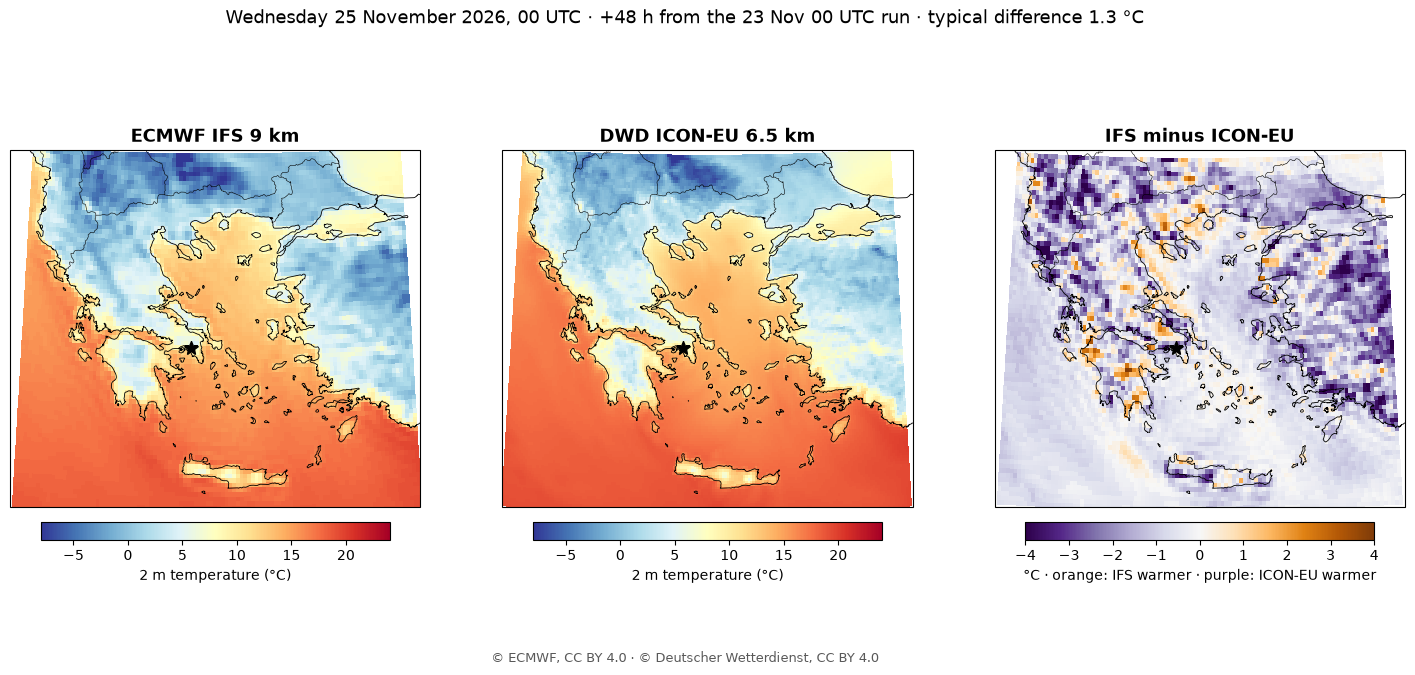

In [5]:
WHEN = None        # hours after the run (3, 6 ... 120); None: +48 h for temperature, the windiest or wettest step otherwise
if WHEN is None:
    WHEN = 48 if VARIABLE == "t2m" else int((ifs.mean(["latitude", "longitude"]) + icon.mean(["latitude", "longitude"])).idxmax())
valid = run + dt.timedelta(hours=WHEN)
proj = ccrs.LambertConformal(central_longitude=24.4, central_latitude=38.3)
fig, axes = plt.subplots(1, 3, figsize=(18, 6.8), subplot_kw=dict(projection=proj))
panels = [(ifs.sel(step=WHEN), "ECMWF IFS 9 km", S["cmap"], S["lim"], S["label"]),
          (icon.sel(step=WHEN), "DWD ICON-EU 6.5 km", S["cmap"], S["lim"], S["label"]),
          (diff.sel(step=WHEN), "IFS minus ICON-EU", "PuOr_r", (-S["dlim"], S["dlim"]),
           f'{S["unit"]} · orange: {S["more"]} · purple: {S["less"]}')]
for ax, (f, title, cmap, (lo, hi), label) in zip(axes, panels):
    ax.set_extent([AREA["west"], AREA["east"], AREA["south"], AREA["north"]], crs=ccrs.PlateCarree())
    m = ax.pcolormesh(f.longitude, f.latitude, f, cmap=cmap, vmin=lo, vmax=hi, shading="auto",
                      transform=ccrs.PlateCarree())
    ax.coastlines("10m", linewidth=0.6); ax.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax.plot(23.728, 37.984, "k*", ms=10, transform=ccrs.PlateCarree())          # Athens
    ax.set_title(title, fontsize=13, fontweight="bold")
    plt.colorbar(m, ax=ax, orientation="horizontal", pad=0.03, shrink=0.85, label=label)
rms = float(np.sqrt((diff.sel(step=WHEN) ** 2).mean()))
fig.suptitle(f"{valid:%A %d %B %Y, %H} UTC · +{WHEN} h from the {run:%d %b %H} UTC run · typical difference {rms:.1f} {S['unit']}",
             fontsize=13)
fig.text(0.5, 0.02, "© ECMWF, CC BY 4.0 · © Deutscher Wetterdienst, CC BY 4.0", ha="center", fontsize=9, color="0.35")
plt.savefig("ifs_vs_icon_map.png", dpi=110, bbox_inches="tight")
plt.show()

### How the difference grows with lead time

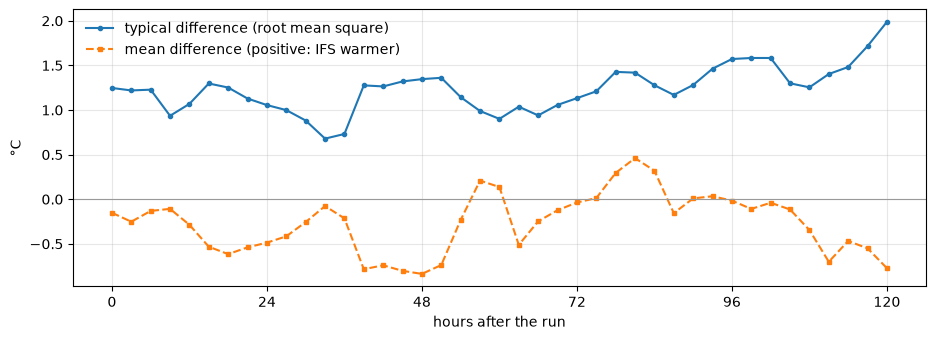

In [6]:
# how far apart the two forecasts are over the whole map, step by step
rms = np.sqrt((diff ** 2).mean(["latitude", "longitude"]))
mean = diff.mean(["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(STEPS, rms, "o-", ms=3, label="typical difference (root mean square)")
ax.plot(STEPS, mean, "s--", ms=3, label=f"mean difference (positive: {S['more']})")
ax.axhline(0, color="0.6", lw=0.8); ax.set_xticks(range(0, 121, 24))
ax.set_xlabel("hours after the run"); ax.set_ylabel(S["unit"]); ax.grid(alpha=0.3); ax.legend(frameon=False)
plt.show()

## 4 · Both models at one place

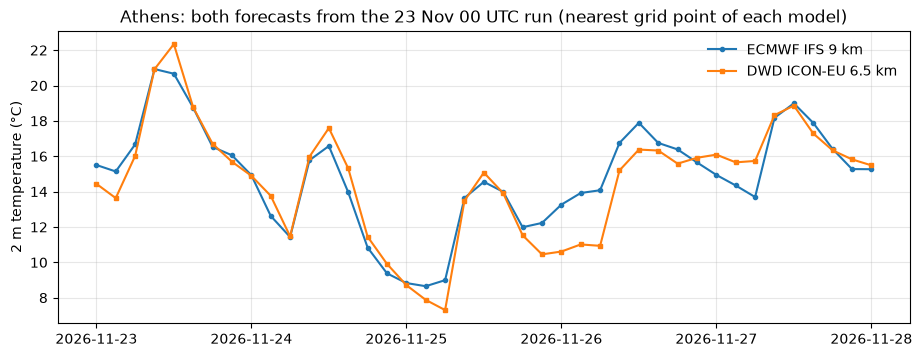

In [7]:
PLACE = ("Athens", 37.984, 23.728)        # or ("Thessaloniki", 40.640, 22.944), ("Heraklion", 35.339, 25.144)
name, la, lo = PLACE
times = [run + dt.timedelta(hours=s) for s in STEPS]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(times, ifs.sel(latitude=la, longitude=lo, method="nearest"), "o-", ms=3, label="ECMWF IFS 9 km")
ax.plot(times, icon.sel(latitude=la, longitude=lo, method="nearest"), "s-", ms=3, label="DWD ICON-EU 6.5 km")
ax.set_ylabel(S["label"]); ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.set_title(f"{name}: both forecasts from the {run:%d %b %H} UTC run (nearest grid point of each model)")
plt.show()

## 5 · Your turn 🌍

- **Another hour:** set `WHEN` in step 3 (for example 12, 60, 108).
- **Another place:** change `PLACE`. Mountain places differ most: each model has its own terrain height.
- **Wind or rain:** set `VARIABLE = "wind"` or `VARIABLE = "precip"` in step 1 and run all again.
- **Another field:** add it to `SETTINGS`. DWD's folder names are on [opendata.dwd.de](https://opendata.dwd.de/weather/nwp/icon-eu/grib/00/)
  (for example `pmsl`, sea level pressure); the IFS names are in the [open data documentation](https://www.ecmwf.int/en/forecasts/datasets/open-data) (`msl`).
- **The machine-learning forecast:** add `model="aifs-single"` to the IFS request and remove `resol="0p1"` (0.25°).

### Data & licence
**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
**DWD open data**, CC BY 4.0: `Source: Deutscher Wetterdienst (opendata.dwd.de)`.
No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [DWD open data](https://opendata.dwd.de) ·
[earthkit](https://earthkit.ecmwf.int)